# Multilingual RAG Results and Visualizations

## Imports & Configs

In [29]:
from __future__ import annotations

import re
import warnings
from pathlib import Path
from typing import Sequence

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm
from sklearn.metrics import cohen_kappa_score, confusion_matrix
from tqdm.auto import tqdm
from IPython.display import display

warnings.filterwarnings("ignore", category=RuntimeWarning)

In [30]:
ROOT = Path.cwd()
if not (ROOT / "data" / "judge step").exists() and (ROOT.parent / "data" / "judge step").exists():
    ROOT = ROOT.parent

JUDGE_DIR = ROOT / "data" / "judge step"
OUTPUT_DIR = ROOT / "results" / "multilingual_judge_analysis"
FIGURE_DIR = OUTPUT_DIR / "figures"
TABLE_DIR = OUTPUT_DIR / "tables"

FIGURE_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)

N_BOOTSTRAP = 2000
RANDOM_SEED = 42
CI_LEVEL = 0.95
CLUSTER_COL = "query_id"

VALID_LABELS = ["ABSTAIN", "INCORRECT", "CORRECT"]
DIFFICULTY_ORDER = ["easy", "medium", "hard"]

print("Repository root:", ROOT)
print("Judge directory:", JUDGE_DIR)
print("Output directory:", OUTPUT_DIR)


Repository root: /Users/martasumyk/Desktop/Paper/rag-uncertainty-eval
Judge directory: /Users/martasumyk/Desktop/Paper/rag-uncertainty-eval/data/judge step
Output directory: /Users/martasumyk/Desktop/Paper/rag-uncertainty-eval/results/multilingual_judge_analysis


In [31]:
LANGUAGE_NAMES = {
    "ar": "Arabic", "de": "German", "en": "English", "es": "Spanish",
    "fa": "Persian", "fi": "Finnish", "fr": "French", "hi": "Hindi",
    "id": "Indonesian", "ja": "Japanese", "ko": "Korean",
    "ru": "Russian", "th": "Thai", "zh": "Chinese",
}

## Utils

## Load data

In [32]:
def infer_metadata(path: Path, df: pd.DataFrame) -> dict[str, str]:
    filename = path.stem.lower()
    judge_provider = path.parent.name.lower()

    if "claude" in filename:
        generator = "Claude Sonnet 4"
    elif "gemini" in filename:
        generator = "Gemini 3.1 Flash-Lite"
    elif "gemma" in filename:
        generator = "Gemma 4 26B"
    elif "gpt54mini" in filename or "gpt5.4" in filename:
        generator = "GPT-5.4-mini"
    elif "qwen" in filename:
        generator = "Qwen 3.6 27B"
    elif "generation_model" in df.columns and df["generation_model"].notna().any():
        generator = str(df["generation_model"].dropna().iloc[0])
    else:
        generator = path.stem

    if "prompt_variant" in df.columns and df["prompt_variant"].notna().any():
        prompt = str(df["prompt_variant"].dropna().iloc[0]).lower()
    else:
        prompt = "advanced" if "advanced" in filename else "simple"

    if "context_mode" in df.columns and df["context_mode"].notna().any():
        context = str(df["context_mode"].dropna().iloc[0]).lower()
    elif "distractor_plus_gold" in filename:
        context = "distractor_plus_gold"
    elif "answer_with_distractor_and_gold" in df.columns:
        context = "distractor_plus_gold"
    else:
        context = "distractor"

    judge_name = {
        "openai": "GPT-5.4-mini",
        "gemini": "Gemini 3.1 Flash-Lite",
        "qwen": "Qwen 3.6 27B",
    }.get(judge_provider, judge_provider)

    return {
        "judge_model": judge_name,
        "judge_provider": judge_provider,
        "generation_model_clean": generator,
        "prompt_variant_clean": prompt,
        "context_mode_clean": context,
        "source_file": path.name,
        "source_path": str(path.relative_to(ROOT)),
    }


In [33]:
csv_paths = sorted(JUDGE_DIR.glob("*/*.csv"))
if not csv_paths:
    raise FileNotFoundError(f"No judged CSVs found under {JUDGE_DIR}")

frames = []
for path in tqdm(csv_paths, desc="Loading judged CSVs"):
    part = pd.read_csv(path)
    for key, value in infer_metadata(path, part).items():
        part[key] = value
    frames.append(part)

results = pd.concat(frames, ignore_index=True, sort=False)

results["judge_label_clean"] = results["judge_label"].astype("string").str.strip().str.upper()
results["language"] = results["language"].astype(str).str.strip().str.lower()
results["language_name"] = results["language"].map(LANGUAGE_NAMES).fillna(results["language"])
results["difficulty_clean"] = results["difficulty"].astype(str).str.strip().str.lower()
results["generation_experiment"] = (
    results["generation_model_clean"] + " | "
    + results["prompt_variant_clean"] + " | "
    + results["context_mode_clean"]
)

print("CSV files:", len(csv_paths))
print("Combined rows:", f"{len(results):,}")
print("Judges:", sorted(results["judge_model"].unique()))
print("Generators:", sorted(results["generation_model_clean"].unique()))
print("Languages:", sorted(results["language"].unique()))

Loading judged CSVs: 100%|██████████| 42/42 [00:08<00:00,  5.23it/s]


CSV files: 42
Combined rows: 176,400
Judges: ['GPT-5.4-mini', 'Gemini 3.1 Flash-Lite', 'Qwen 3.6 27B']
Generators: ['Claude Sonnet 4', 'GPT-5.4-mini', 'Gemini 3.1 Flash-Lite', 'Gemma 4 26B', 'Qwen 3.6 27B']
Languages: ['ar', 'de', 'en', 'es', 'fa', 'fi', 'fr', 'hi', 'id', 'ja', 'ko', 'ru', 'th', 'zh']


In [34]:
analysis_df = results[results["judge_label_clean"].isin(VALID_LABELS)].copy()

In [70]:
overall_groups = [
    "judge_model", "generation_model_clean",
    "prompt_variant_clean", "context_mode_clean",
]

overall_ci = add_percentage_columns(
    grouped_bootstrap_rates(analysis_df, overall_groups)
)

overall_ci.to_csv(TABLE_DIR / "overall_rates_with_bootstrap_ci.csv", index=False)

overall_paper = (
    overall_ci.pivot_table(
        index=overall_groups,
        columns="label",
        values="rate_ci",
        aggfunc="first",
    )
    .reset_index()
)

overall_paper.to_csv(TABLE_DIR / "overall_paper_table.csv", index=False)
(TABLE_DIR / "overall_paper_table.tex").write_text(
    overall_paper.to_latex(
        index=False,
        escape=True,
        caption="Judge-label rates with 95\\% cluster-bootstrap confidence intervals.",
        label="tab:multilingual-overall-results",
    ),
    encoding="utf-8",
)


Bootstrap groups: 100%|██████████| 42/42 [00:02<00:00, 14.42it/s]


5366

In [71]:
language_groups = [
    "judge_model", "generation_model_clean", "prompt_variant_clean",
    "context_mode_clean", "language", "language_name",
]

language_ci = add_percentage_columns(
    grouped_bootstrap_rates(analysis_df, language_groups)
)
language_ci.to_csv(TABLE_DIR / "rates_by_language_with_bootstrap_ci.csv", index=False)

language_incorrect = language_ci[language_ci["label"] == "INCORRECT"].copy()
# display(language_incorrect.head(30))


Bootstrap groups: 100%|██████████| 588/588 [00:18<00:00, 31.12it/s]


In [35]:
def cluster_bootstrap_rate(
    df: pd.DataFrame,
    target_label: str,
    cluster_col: str = CLUSTER_COL,
    n_boot: int = N_BOOTSTRAP,
    seed: int = RANDOM_SEED,
    ci_level: float = CI_LEVEL,
) -> dict[str, float]:
    work = df[[cluster_col, "judge_label_clean"]].dropna().copy()

    if work.empty:
        return {
            "n_rows": 0, "n_clusters": 0, "rate": np.nan,
            "ci_low": np.nan, "ci_high": np.nan,
            "normal_ci_low": np.nan, "normal_ci_high": np.nan,
            "bootstrap_sd": np.nan,
        }

    cluster_stats = (
        work.assign(is_target=(work["judge_label_clean"] == target_label).astype(int))
        .groupby(cluster_col, sort=False)["is_target"]
        .agg(["sum", "count"])
    )

    successes = cluster_stats["sum"].to_numpy(dtype=float)
    totals = cluster_stats["count"].to_numpy(dtype=float)
    n_clusters = len(cluster_stats)

    rng = np.random.default_rng(seed)
    boot = np.empty(n_boot, dtype=float)

    for b in range(n_boot):
        sampled = rng.integers(0, n_clusters, size=n_clusters)
        boot[b] = successes[sampled].sum() / totals[sampled].sum()

    alpha = 1 - ci_level
    ci_low, ci_high = np.quantile(boot, [alpha / 2, 1 - alpha / 2])

    z = norm.ppf(1 - alpha / 2)
    boot_mean = float(boot.mean())
    boot_sd = float(boot.std(ddof=1))

    return {
        "n_rows": int(len(work)),
        "n_clusters": int(n_clusters),
        "rate": float((work["judge_label_clean"] == target_label).mean()),
        "ci_low": float(ci_low),
        "ci_high": float(ci_high),
        "normal_ci_low": float(max(0, boot_mean - z * boot_sd)),
        "normal_ci_high": float(min(1, boot_mean + z * boot_sd)),
        "bootstrap_sd": boot_sd,
    }


def grouped_bootstrap_rates(
    df: pd.DataFrame,
    group_cols: Sequence[str],
    labels: Sequence[str] = VALID_LABELS,
    n_boot: int = N_BOOTSTRAP,
) -> pd.DataFrame:
    rows = []
    grouped = df.groupby(list(group_cols), dropna=False, sort=False)

    for values, group in tqdm(grouped, desc="Bootstrap groups"):
        if not isinstance(values, tuple):
            values = (values,)
        meta = dict(zip(group_cols, values))

        for label in labels:
            rows.append({
                **meta,
                "label": label,
                **cluster_bootstrap_rate(group, label, n_boot=n_boot),
            })

    return pd.DataFrame(rows)


def add_percentage_columns(table: pd.DataFrame) -> pd.DataFrame:
    table = table.copy()
    for col in ["rate", "ci_low", "ci_high", "normal_ci_low", "normal_ci_high", "bootstrap_sd"]:
        table[f"{col}_pct"] = 100 * table[col]
    table["rate_ci"] = table.apply(
        lambda r: f"{r['rate_pct']:.1f} [{r['ci_low_pct']:.1f}, {r['ci_high_pct']:.1f}]",
        axis=1,
    )
    return table


def save_figure(name: str) -> None:
    plt.tight_layout()
    plt.savefig(FIGURE_DIR / f"{name}.png", dpi=300, bbox_inches="tight")
    plt.savefig(FIGURE_DIR / f"{name}.pdf", bbox_inches="tight")
    plt.show()


## 1. Per language analysis

### 1.1. Incorrect rate by language

In [72]:
language_aggregate = add_percentage_columns(
    grouped_bootstrap_rates(
        analysis_df[analysis_df["context_mode_clean"] == "distractor"],
        ["generation_model_clean", "prompt_variant_clean", "language", "language_name"],
        labels=["INCORRECT"],
    )
)

Bootstrap groups: 100%|██████████| 140/140 [00:01<00:00, 79.11it/s]


In [79]:
language_model_average = add_percentage_columns(
    grouped_bootstrap_rates(
        analysis_df[
            analysis_df["context_mode_clean"] == "distractor"
        ],
        [
            "generation_model_clean",
            "language",
            "language_name",
        ],
        labels=["INCORRECT"],
    )
)

language_model_average = language_model_average[
    language_model_average["label"] == "INCORRECT"
].copy()

Bootstrap groups: 100%|██████████| 70/70 [00:01<00:00, 65.66it/s]


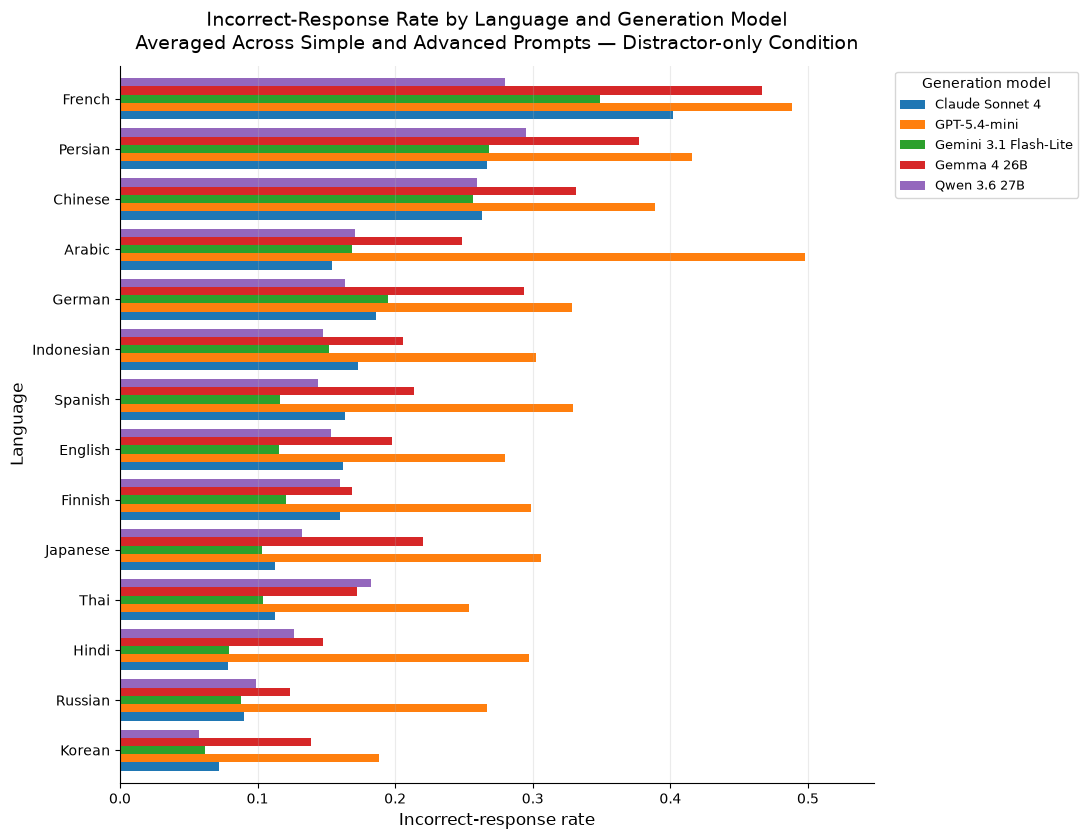

In [80]:
pivot = language_model_average.pivot(
    index="language_name",
    columns="generation_model_clean",
    values="rate",
)

language_order = (
    pivot.mean(axis=1)
    .sort_values(ascending=True)
    .index
)

pivot = pivot.loc[language_order]

ax = pivot.plot(
    kind="barh",
    figsize=(11, 8.5),
    width=0.82,
)

ax.set_xlabel(
    "Incorrect-response rate",
    fontsize=12,
)

ax.set_ylabel(
    "Language",
    fontsize=12,
)

ax.set_title(
    "Incorrect-Response Rate by Language and Generation Model\n"
    "Averaged Across Simple and Advanced Prompts — Distractor-only Condition",
    fontsize=14,
    pad=12,
)

ax.legend(
    title="Generation model",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    fontsize=9,
)

ax.grid(
    axis="x",
    alpha=0.25,
)

ax.tick_params(
    axis="x",
    labelsize=10,
)

ax.tick_params(
    axis="y",
    labelsize=10,
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.set_xlim(
    0,
    pivot.max().max() + 0.05,
)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "incorrect_by_language_and_model_prompt_averaged.png",
    dpi=300,
    bbox_inches="tight",
)

plt.savefig(
    FIGURE_DIR / "incorrect_by_language_and_model_prompt_averaged.pdf",
    bbox_inches="tight",
)

plt.show()

Averaged across models:

In [74]:
language_average = add_percentage_columns(
    grouped_bootstrap_rates(
        analysis_df[
            analysis_df["context_mode_clean"] == "distractor"
        ],
        ["language", "language_name"],
        labels=["INCORRECT"],
    )
)

language_average = (
    language_average[
        language_average["label"] == "INCORRECT"
    ]
    .sort_values("rate_pct", ascending=True)
    .reset_index(drop=True)
)

Bootstrap groups: 100%|██████████| 14/14 [00:00<00:00, 50.94it/s]


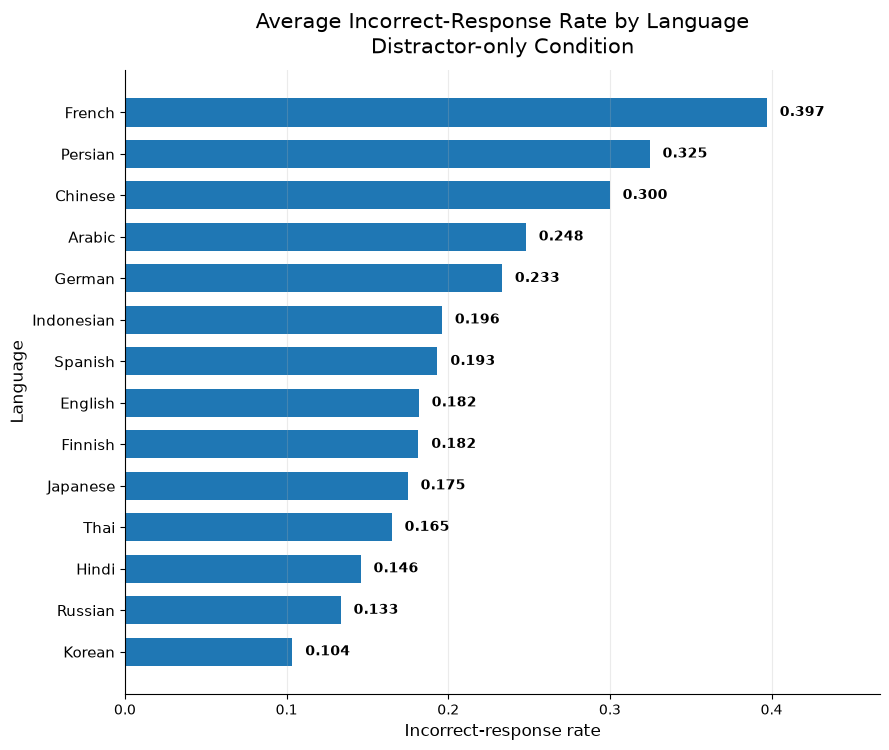

In [92]:
y_positions = np.arange(len(language_average))
values = language_average["rate"].to_numpy()

fig, ax = plt.subplots(figsize=(9, 8))

bars = ax.barh(
    y_positions,
    values,
    height=0.68,
)

ax.set_yticks(y_positions)
ax.set_yticklabels(
    language_average["language_name"],
    fontsize=11,
)

ax.set_xlabel(
    "Incorrect-response rate",
    fontsize=12,
)

ax.set_ylabel(
    "Language",
    fontsize=12,
)

ax.set_title(
    "Average Incorrect-Response Rate by Language\n"
    "Distractor-only Condition",
    fontsize=15,
    pad=12,
)

ax.grid(
    axis="x",
    alpha=0.25,
)

ax.tick_params(
    axis="x",
    labelsize=10,
)

for bar, rate in zip(
    bars,
    language_average["rate"],
):
    ax.text(
        rate + 0.008,
        bar.get_y() + bar.get_height() / 2,
        f"{rate:.3f}",
        va="center",
        ha="left",
        fontsize=10,
        fontweight="bold",
    )

ax.set_xlim(
    0,
    language_average["rate"].max() + 0.07,
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout(rect=[0, 0.05, 1, 1])

plt.savefig(
    FIGURE_DIR / "average_incorrect_rate_by_language_no_ci.png",
    dpi=300,
    bbox_inches="tight",
)

plt.savefig(
    FIGURE_DIR / "average_incorrect_rate_by_language_no_ci.pdf",
    bbox_inches="tight",
)

plt.show()

## 2. Analysis by difficulty levels

In [81]:
difficulty_groups = [
    "judge_model", "generation_model_clean",
    "prompt_variant_clean", "context_mode_clean", "difficulty_clean",
]

difficulty_ci = add_percentage_columns(
    grouped_bootstrap_rates(
        analysis_df[analysis_df["difficulty_clean"].isin(DIFFICULTY_ORDER)],
        difficulty_groups,
    )
)
difficulty_ci.to_csv(TABLE_DIR / "rates_by_difficulty_with_bootstrap_ci.csv", index=False)

difficulty_aggregate = add_percentage_columns(
    grouped_bootstrap_rates(
        analysis_df[
            (analysis_df["context_mode_clean"] == "distractor")
            & analysis_df["difficulty_clean"].isin(DIFFICULTY_ORDER)
        ],
        ["generation_model_clean", "prompt_variant_clean", "difficulty_clean"],
        labels=["INCORRECT"],
    )
)

Bootstrap groups: 100%|██████████| 30/30 [00:01<00:00, 22.38it/s]


### 2.1. Incorrect responses rate by difficulty level

In [87]:
difficulty_prompt_average = add_percentage_columns(
    grouped_bootstrap_rates(
        analysis_df[
            (analysis_df["context_mode_clean"] == "distractor")
            & analysis_df["difficulty_clean"].isin(DIFFICULTY_ORDER)
        ],
        [
            "generation_model_clean",
            "difficulty_clean",
        ],
        labels=["INCORRECT"],
    )
)

difficulty_prompt_average = difficulty_prompt_average[
    difficulty_prompt_average["label"] == "INCORRECT"
].copy()

Bootstrap groups: 100%|██████████| 15/15 [00:00<00:00, 18.47it/s]


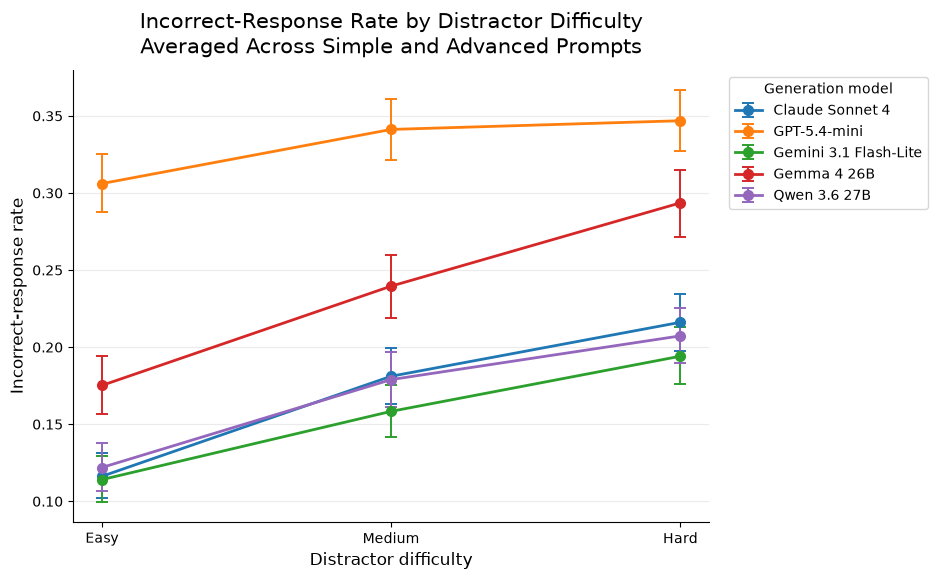

In [88]:
fig, ax = plt.subplots(figsize=(9.5, 6.2))

for model, group in difficulty_prompt_average.groupby(
    "generation_model_clean"
):
    group = (
        group.set_index("difficulty_clean")
        .reindex(DIFFICULTY_ORDER)
        .reset_index()
    )

    rates = group["rate"].to_numpy()

    lower_errors = (
        rates - group["ci_low"].to_numpy()
    )

    upper_errors = (
        group["ci_high"].to_numpy() - rates
    )

    ax.errorbar(
        DIFFICULTY_ORDER,
        rates,
        yerr=np.vstack([lower_errors, upper_errors]),
        marker="o",
        markersize=7,
        linewidth=2,
        capsize=4,
        capthick=1.4,
        elinewidth=1.4,
        label=model,
    )

ax.set_xlabel(
    "Distractor difficulty",
    fontsize=12,
)

ax.set_ylabel(
    "Incorrect-response rate",
    fontsize=12,
)

ax.set_title(
    "Incorrect-Response Rate by Distractor Difficulty\n"
    "Averaged Across Simple and Advanced Prompts",
    fontsize=15,
    pad=12,
)

ax.set_xticks(
    np.arange(len(DIFFICULTY_ORDER)),
    [difficulty.capitalize() for difficulty in DIFFICULTY_ORDER],
)

ax.grid(
    axis="y",
    alpha=0.25,
)

ax.legend(
    title="Generation model",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout(rect=[0, 0.05, 1, 1])

plt.savefig(
    FIGURE_DIR / "incorrect_by_difficulty_prompt_averaged.png",
    dpi=300,
    bbox_inches="tight",
)

plt.savefig(
    FIGURE_DIR / "incorrect_by_difficulty_prompt_averaged.pdf",
    bbox_inches="tight",
)

plt.show()

### 2.2. Correct responses rate by difficulty

In [90]:
difficulty_correct_average = add_percentage_columns(
    grouped_bootstrap_rates(
        analysis_df[
            (analysis_df["context_mode_clean"] == "distractor")
            & analysis_df["difficulty_clean"].isin(DIFFICULTY_ORDER)
        ],
        [
            "generation_model_clean",
            "difficulty_clean",
        ],
        labels=["CORRECT"],
    )
)

difficulty_correct_average = difficulty_correct_average[
    difficulty_correct_average["label"] == "CORRECT"
].copy()

Bootstrap groups: 100%|██████████| 15/15 [00:00<00:00, 25.51it/s]


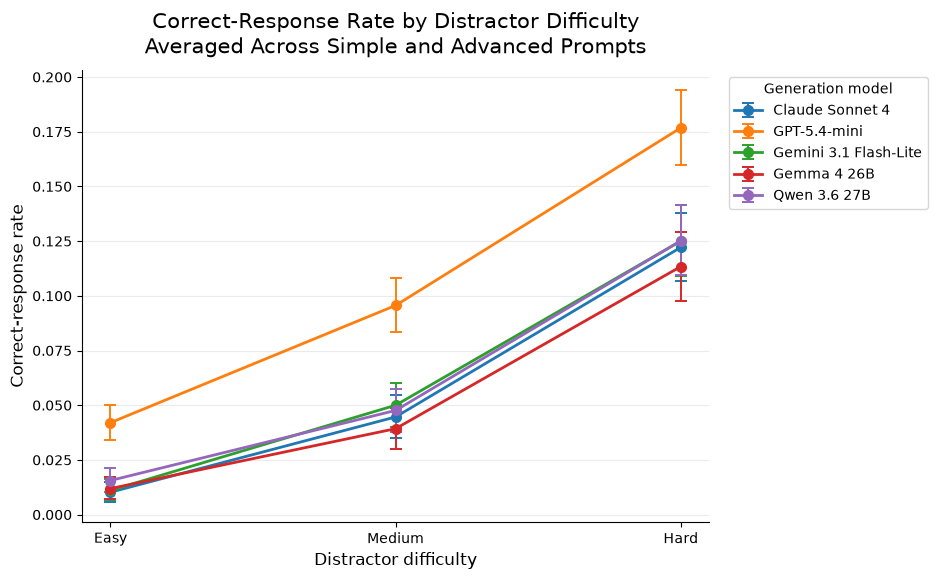

In [ ]:
fig, ax = plt.subplots(figsize=(9.5, 6.2))

for model, group in difficulty_correct_average.groupby(
    "generation_model_clean"
):
    group = (
        group.set_index("difficulty_clean")
        .reindex(DIFFICULTY_ORDER)
        .reset_index()
    )

    rates = group["rate"].to_numpy()

    lower_errors = (
        rates - group["ci_low"].to_numpy()
    )

    upper_errors = (
        group["ci_high"].to_numpy() - rates
    )

    ax.errorbar(
        DIFFICULTY_ORDER,
        rates,
        yerr=np.vstack([lower_errors, upper_errors]),
        marker="o",
        markersize=7,
        linewidth=2,
        capsize=4,
        capthick=1.4,
        elinewidth=1.4,
        label=model,
    )

ax.set_xlabel(
    "Distractor difficulty",
    fontsize=12,
)

ax.set_ylabel(
    "Correct-response rate",
    fontsize=12,
)

ax.set_title(
    "Correct-Response Rate by Distractor Difficulty\n"
    "Averaged Across Simple and Advanced Prompts",
    fontsize=15,
    pad=12,
)

ax.set_xticks(
    np.arange(len(DIFFICULTY_ORDER)),
    [difficulty.capitalize() for difficulty in DIFFICULTY_ORDER],
)

ax.grid(
    axis="y",
    alpha=0.25,
)

ax.legend(
    title="Generation model",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout(rect=[0, 0.05, 1, 1])

plt.savefig(
    FIGURE_DIR / "correct_by_difficulty_prompt_averaged.png",
    dpi=300,
    bbox_inches="tight",
)

plt.savefig(
    FIGURE_DIR / "correct_by_difficulty_prompt_averaged.pdf",
    bbox_inches="tight",
)

plt.show()

## 3. Intra-model agreement

In [95]:
agreement_keys = [
    c for c in [
        "language", "query_id", "distractor_id",
        "generation_model_clean", "prompt_variant_clean", "context_mode_clean",
    ]
    if c in analysis_df.columns
]

judge_wide = (
    analysis_df.pivot_table(
        index=agreement_keys,
        columns="judge_model",
        values="judge_label_clean",
        aggfunc="first",
    )
    .reset_index()
)

judge_names = sorted(analysis_df["judge_model"].unique())
agreement_rows = []

for i, judge_a in enumerate(judge_names):
    for judge_b in judge_names[i + 1:]:
        pair = judge_wide[[judge_a, judge_b]].dropna()
        if pair.empty:
            continue

        agreement_rows.append({
            "judge_a": judge_a,
            "judge_b": judge_b,
            "exact_agreement": (pair[judge_a] == pair[judge_b]).mean(),
            "cohen_kappa": cohen_kappa_score(
                pair[judge_a], pair[judge_b], labels=VALID_LABELS
            ),
        })

        matrix = pd.DataFrame(
            confusion_matrix(
                pair[judge_a], pair[judge_b], labels=VALID_LABELS
            ),
            index=[f"{judge_a}: {x}" for x in VALID_LABELS],
            columns=[f"{judge_b}: {x}" for x in VALID_LABELS],
        )

        safe_a = re.sub(r"[^a-z0-9]+", "_", judge_a.lower()).strip("_")
        safe_b = re.sub(r"[^a-z0-9]+", "_", judge_b.lower()).strip("_")
        matrix.to_csv(TABLE_DIR / f"confusion_{safe_a}_vs_{safe_b}.csv")

judge_agreement = pd.DataFrame(agreement_rows)
judge_agreement.to_csv(TABLE_DIR / "pairwise_judge_agreement.csv", index=False)
display(judge_agreement)


,judge_a,judge_b,exact_agreement,cohen_kappa
0,GPT-5.4-mini,Gemini 3.1 Flash-Lite,0.948707,0.912220
1,GPT-5.4-mini,Qwen 3.6 27B,0.952772,0.918511
2,Gemini 3.1 Flash-Lite,Qwen 3.6 27B,0.962370,0.935176


Text(0, 0.5, 'Judge model')

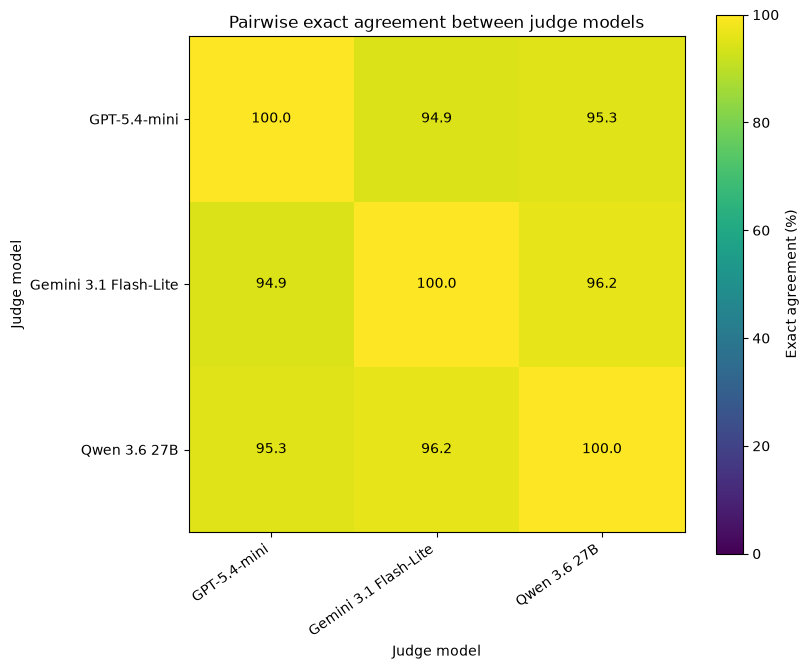

In [93]:
exact_matrix = pd.DataFrame(
    np.eye(len(judge_names)),
    index=judge_names,
    columns=judge_names,
    dtype=float,
)

kappa_matrix = pd.DataFrame(
    np.eye(len(judge_names)),
    index=judge_names,
    columns=judge_names,
    dtype=float,
)

for _, row in judge_agreement.iterrows():
    judge_a = row["judge_a"]
    judge_b = row["judge_b"]

    exact_matrix.loc[judge_a, judge_b] = row["exact_agreement"]
    exact_matrix.loc[judge_b, judge_a] = row["exact_agreement"]

    kappa_matrix.loc[judge_a, judge_b] = row["cohen_kappa"]
    kappa_matrix.loc[judge_b, judge_a] = row["cohen_kappa"]


plt.figure(figsize=(8, 7))

image = plt.imshow(
    exact_matrix.to_numpy() * 100,
    vmin=0,
    vmax=100,
    aspect="equal",
)

plt.xticks(
    np.arange(len(judge_names)),
    judge_names,
    rotation=35,
    ha="right",
)

plt.yticks(
    np.arange(len(judge_names)),
    judge_names,
)

for i in range(len(judge_names)):
    for j in range(len(judge_names)):
        value = exact_matrix.iloc[i, j] * 100
        plt.text(
            j,
            i,
            f"{value:.1f}",
            ha="center",
            va="center",
        )

plt.colorbar(image, label="Exact agreement (%)")
plt.title("Pairwise exact agreement between judge models")
plt.xlabel("Judge model")
plt.ylabel("Judge model")

Text(0, 0.5, 'Judge model')

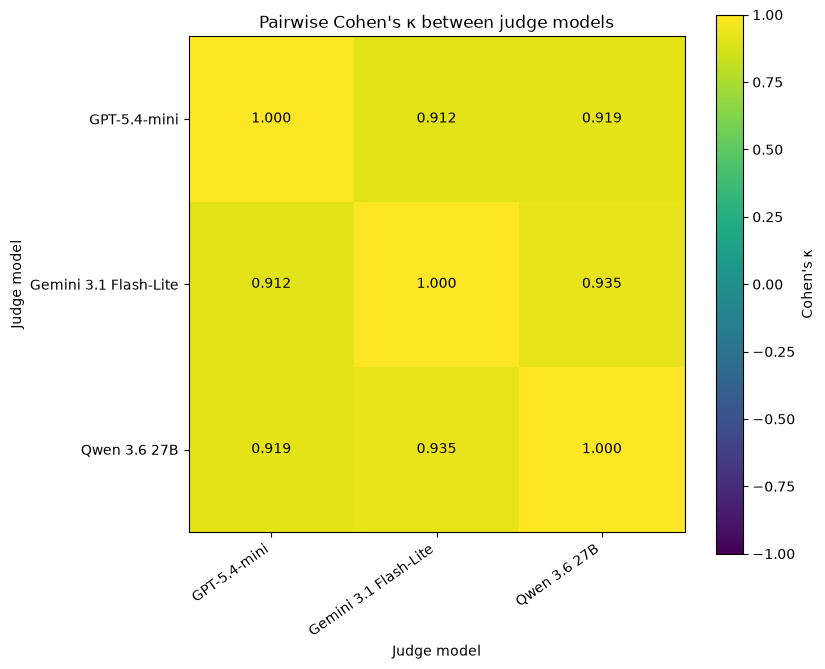

In [94]:


plt.figure(figsize=(8, 7))

image = plt.imshow(
    kappa_matrix.to_numpy(),
    vmin=-1,
    vmax=1,
    aspect="equal",
)

plt.xticks(
    np.arange(len(judge_names)),
    judge_names,
    rotation=35,
    ha="right",
)

plt.yticks(
    np.arange(len(judge_names)),
    judge_names,
)

for i in range(len(judge_names)):
    for j in range(len(judge_names)):
        value = kappa_matrix.iloc[i, j]

        plt.text(
            j,
            i,
            f"{value:.3f}",
            ha="center",
            va="center",
        )

plt.colorbar(image, label="Cohen's κ")
plt.title("Pairwise Cohen's κ between judge models")
plt.xlabel("Judge model")
plt.ylabel("Judge model")

## 4. Similarity vs rate of incorrect responses

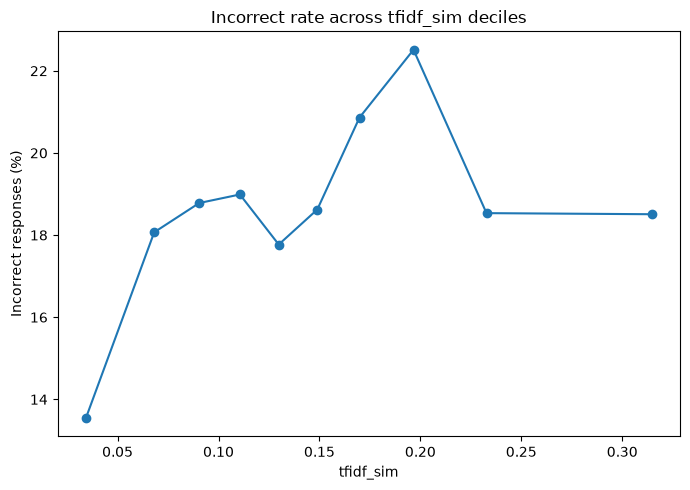

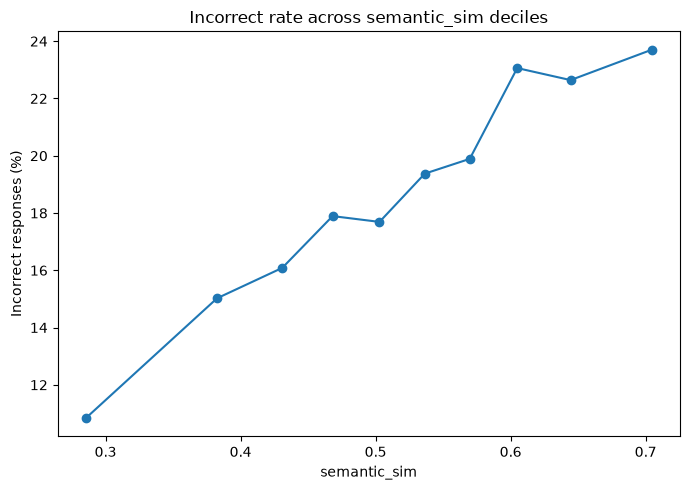

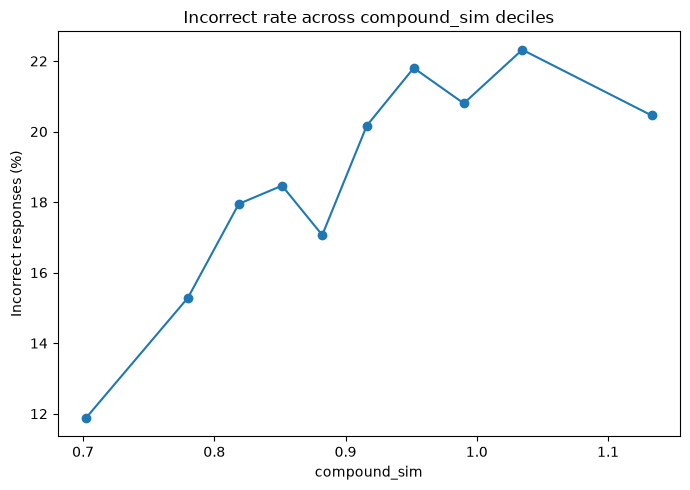

In [44]:
similarity_cols = [
    c for c in ["tfidf_sim", "semantic_sim", "compound_sim"]
    if c in analysis_df.columns
]

similarity_tables = []

for similarity_col in similarity_cols:
    work = analysis_df[[similarity_col, "judge_label_clean"]].dropna().copy()
    work["is_incorrect"] = (work["judge_label_clean"] == "INCORRECT").astype(int)
    work["bin"] = pd.qcut(work[similarity_col], q=10, duplicates="drop")

    table = (
        work.groupby("bin", observed=True)
        .agg(
            similarity_mean=(similarity_col, "mean"),
            incorrect_rate=("is_incorrect", "mean"),
            n=("is_incorrect", "size"),
        )
        .reset_index(drop=True)
    )
    table["similarity_metric"] = similarity_col
    similarity_tables.append(table)

    plt.figure(figsize=(7, 5))
    plt.plot(
        table["similarity_mean"],
        100 * table["incorrect_rate"],
        marker="o",
    )
    plt.xlabel(similarity_col)
    plt.ylabel("Incorrect responses (%)")
    plt.title(f"Incorrect rate across {similarity_col} deciles")
    save_figure(f"incorrect_by_{similarity_col}_decile")

similarity_summary = pd.concat(similarity_tables, ignore_index=True)
similarity_summary.to_csv(
    TABLE_DIR / "incorrect_rate_by_similarity_decile.csv",
    index=False,
)


## 5. Effect of advanced prompt

In [ ]:
def paired_prompt_effect_bootstrap(
    df: pd.DataFrame,
    target_label: str = "INCORRECT",
    cluster_col: str = "query_id",
    n_boot: int = 2000,
    seed: int = 42,
) -> dict[str, float]:

    work = df[
        df["prompt_variant_clean"].isin(["simple", "advanced"])
    ].copy()

    work["is_target"] = (
        work["judge_label_clean"] == target_label
    ).astype(float)

    per_query = (
        work.groupby(
            [cluster_col, "prompt_variant_clean"],
            dropna=False,
        )["is_target"]
        .mean()
        .unstack("prompt_variant_clean")
    )

    per_query = per_query.dropna(
        subset=["simple", "advanced"]
    )

    if per_query.empty:
        return {
            "n_clusters": 0,
            "simple_rate": np.nan,
            "advanced_rate": np.nan,
            "difference": np.nan,
            "ci_low": np.nan,
            "ci_high": np.nan,
            "bootstrap_sd": np.nan,
            "probability_reduction": np.nan,
        }

    simple_values = per_query["simple"].to_numpy()
    advanced_values = per_query["advanced"].to_numpy()

    differences = advanced_values - simple_values

    rng = np.random.default_rng(seed)
    n_clusters = len(per_query)

    bootstrap_differences = np.empty(
        n_boot,
        dtype=float,
    )

    for bootstrap_idx in range(n_boot):
        sampled_indices = rng.integers(
            0,
            n_clusters,
            size=n_clusters,
        )

        bootstrap_differences[bootstrap_idx] = (
            differences[sampled_indices].mean()
        )

    return {
        "n_clusters": n_clusters,
        "simple_rate": float(simple_values.mean()),
        "advanced_rate": float(advanced_values.mean()),
        "difference": float(differences.mean()),
        "ci_low": float(
            np.quantile(bootstrap_differences, 0.025)
        ),
        "ci_high": float(
            np.quantile(bootstrap_differences, 0.975)
        ),
        "bootstrap_sd": float(
            bootstrap_differences.std(ddof=1)
        ),
        "probability_reduction": float(
            (bootstrap_differences < 0).mean()
        ),
    }

In [108]:
aggregate_groups = [
    "generation_model_clean",
    "context_mode_clean",
]

aggregate_rows = []

for group_values, group_df in tqdm(
    analysis_df.groupby(
        aggregate_groups,
        dropna=False,
    ),
    desc="Aggregate prompt effects",
):
    if not isinstance(group_values, tuple):
        group_values = (group_values,)

    metadata = dict(
        zip(aggregate_groups, group_values)
    )

    result = paired_prompt_effect_bootstrap(
        group_df,
        target_label="INCORRECT",
        cluster_col="query_id",
        n_boot=N_BOOTSTRAP,
        seed=RANDOM_SEED,
    )

    aggregate_rows.append(
        {
            **metadata,
            **result,
        }
    )

prompt_effect_aggregate = pd.DataFrame(
    aggregate_rows
)

for column in [
    "simple_rate",
    "advanced_rate",
    "difference",
    "ci_low",
    "ci_high",
]:
    prompt_effect_aggregate[
        f"{column}_pct"
    ] = prompt_effect_aggregate[column] * 100

Aggregate prompt effects: 100%|██████████| 7/7 [00:01<00:00,  6.70it/s]


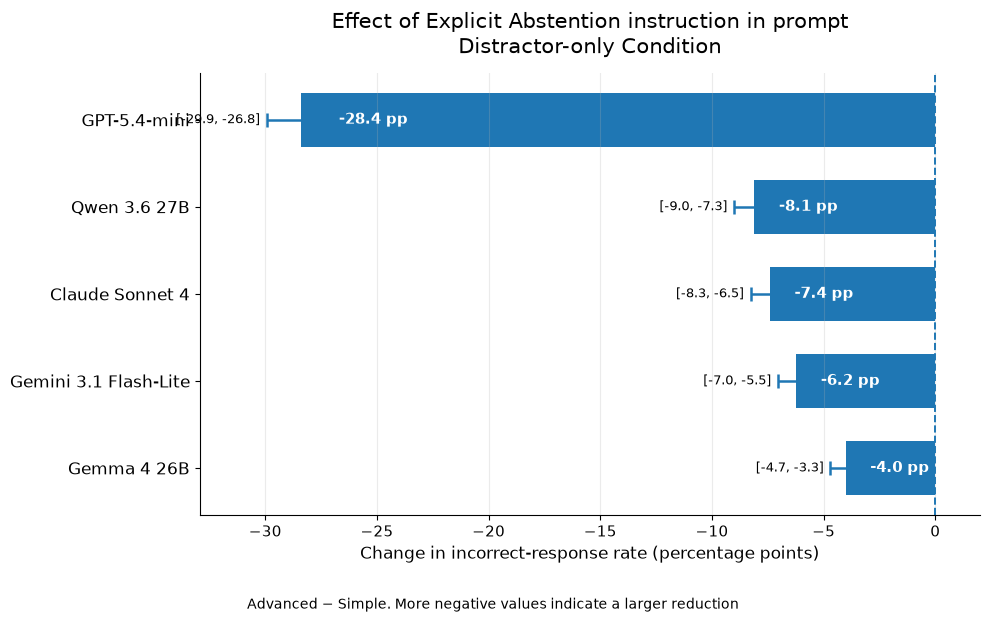

In [109]:
plot_df = (
    prompt_effect_aggregate[
        prompt_effect_aggregate["context_mode_clean"] == "distractor"
    ]
    .dropna(subset=["difference_pct", "ci_low_pct", "ci_high_pct"])
    .sort_values("difference_pct")
    .reset_index(drop=True)
)

y_positions = np.arange(len(plot_df))

values = plot_df["difference_pct"].to_numpy()

lower_errors = (
    values
    - plot_df["ci_low_pct"].to_numpy()
)

upper_errors = (
    plot_df["ci_high_pct"].to_numpy()
    - values
)

fig, ax = plt.subplots(figsize=(10, 6.2))

bars = ax.barh(
    y_positions,
    values,
    height=0.62,
)

ax.errorbar(
    values,
    y_positions,
    xerr=np.vstack([lower_errors, upper_errors]),
    fmt="none",
    capsize=5,
    capthick=1.8,
    elinewidth=1.8,
    zorder=3,
)

ax.axvline(
    0,
    linestyle="--",
    linewidth=1.4,
)

ax.set_yticks(y_positions)
ax.set_yticklabels(
    plot_df["generation_model_clean"],
    fontsize=12,
)

ax.invert_yaxis()

ax.set_xlabel(
    "Change in incorrect-response rate (percentage points)",
    fontsize=12,
)

ax.set_title(
    "Effect of Explicit Abstention instruction in prompt\n"
    "Distractor-only Condition",
    fontsize=15,
    pad=14,
)

ax.grid(
    axis="x",
    alpha=0.25,
    linewidth=0.8,
)

ax.tick_params(
    axis="x",
    labelsize=11,
)

minimum_x = min(
    plot_df["ci_low_pct"].min(),
    values.min(),
)

ax.set_xlim(
    minimum_x - 3,
    2,
)

for bar, value, ci_low, ci_high in zip(
    bars,
    values,
    plot_df["ci_low_pct"],
    plot_df["ci_high_pct"],
):
    bar_width = abs(value)

    text_x = value + max(1.1, bar_width * 0.06)

    ax.text(
        text_x,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.1f} pp",
        va="center",
        ha="left",
        fontsize=11,
        fontweight="bold",
        color="white",
    )

    ax.text(
        ci_low - 0.3,
        bar.get_y() + bar.get_height() / 2,
        f"[{ci_low:.1f}, {ci_high:.1f}]",
        va="center",
        ha="right",
        fontsize=9,
    )

fig.text(
    0.5,
    0.01,
    "Advanced − Simple. More negative values indicate a larger reduction ",
    ha="center",
    fontsize=10,
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout(rect=[0, 0.06, 1, 1])

plt.savefig(
    FIGURE_DIR / "prompt_effect_distractor_only_improved.png",
    dpi=300,
    bbox_inches="tight",
)

plt.savefig(
    FIGURE_DIR / "prompt_effect_distractor_only_improved.pdf",
    bbox_inches="tight",
)

plt.show()

Incorrect rate: simple vs advanced prompt:

In [110]:
table = (
    prompt_effect_aggregate[
        prompt_effect_aggregate["context_mode_clean"] == "distractor"
    ]
    .copy()
    .sort_values("difference_pct")
    .reset_index(drop=True)
)

table["Simple prompt"] = table["simple_rate_pct"].map(
    lambda x: f"{x:.1f}%"
)

table["Advanced prompt"] = table.apply(
    lambda r:
        f"{r['advanced_rate_pct']:.1f}% "
        f"({r['difference_pct']:.1f})",
    axis=1,
)

paper_table = table[
    [
        "generation_model_clean",
        "Simple prompt",
        "Advanced prompt",
    ]
].rename(
    columns={
        "generation_model_clean": "Generation model",
    }
)

display(paper_table)


,Generation model,Simple prompt,Advanced prompt
0,GPT-5.4-mini,47.4%,18.9% (-28.4)
1,Qwen 3.6 27B,21.1%,13.0% (-8.1)
2,Claude Sonnet 4,21.0%,13.6% (-7.4)
3,Gemini 3.1 Flash-Lite,18.7%,12.5% (-6.2)
4,Gemma 4 26B,25.8%,21.7% (-4.0)
